# Descriptives

## TOC 

- [Setup & Git](#setup)
- [Load and Preprocess Kern et al. & GPT Tweets](#load_preprocess_tweets)
- [Compare Prevalences](#compare_prevalences)
- [Check for Order Effects](#order_effects)

# Stuff to Check For / Analysis Ideas
- compare prevalences with those from Kern et al Paper 
- calculate agreement per tweets across the different conditions
- order effects (compare batch prompted with single-tweet prompted tweets)
- compare uncertainty measures per conditions (empirical entropy, confidence scores, etc.)

<a id="setup"></a>
## Setup & Git

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import os 
import pandas as pd
import re

<a id="load_preprocess_tweets"></a>
## Load and Preprocess the GPT Labelled Tweets

### Load and rbind the GPT Labeled Tweets

In [19]:
# load the ZERO-SHOT annotations 
DATE_TO_IMPORT = '2025_04_10'

files = os.listdir('Data_Collection/')
files_to_select = list(filter(lambda filename: filename.startswith(DATE_TO_IMPORT), files))
files_to_select = [f"Data_Collection/{filename}" for filename in files_to_select]

# read and concat files 
dataframes = [pd.read_csv(file) for file in files_to_select]
combined_df_z = pd.concat(dataframes, sort=False, ignore_index=True)
combined_df_z.sort_values(['batch_id', 'tweet_in_batch'], inplace=True)


# load the FEW-SHOT annotations 
DATE_TO_IMPORT = '2025_06_12'

files = os.listdir('Data_Collection/OL_NHS')
files_to_select = list(filter(lambda filename: filename.startswith(DATE_TO_IMPORT), files))
files_to_select = [f"Data_Collection/OL_NHS/{filename}" for filename in files_to_select]

# read and concat files 
dataframes = [pd.read_csv(file) for file in files_to_select]
combined_df_f = pd.concat(dataframes, sort=False, ignore_index=True)
combined_df_f.sort_values(['batch_id', 'tweet_in_batch'], inplace=True)

# Concat the tweets and add zero- vs. few-shot column
combined_df_z.insert(5,'shot','zero-shot')
combined_df_f.insert(5,'shot','few-shot')
combined_df = pd.concat([combined_df_z, 
                         combined_df_f], sort=False, ignore_index=True)


# Sekect combined df subset 
combined_df = combined_df[combined_df['shot'] == 'few-shot']


n_tweets = len(combined_df['tweet'].drop_duplicates())
n_tweet_batches = len(combined_df['batch_id'].drop_duplicates())
n_conditions = len(combined_df['condition'].drop_duplicates())
# conditions = combined_df['condition'].drop_duplicates()


print(f'Unique Tweets: {n_tweets}')
print(f'No. Batches: {n_tweet_batches}')
# print(f'Conditions: {n_conditions} --> {conditions}')

combined_df[combined_df['tweet_id'] == 1371].head(2)

Unique Tweets: 120
No. Batches: 20


,batch_id,tweet_in_batch,tweet_id,tweet,condition,shot,R1_label,R2_label,R3_label,R1_score,...,R3_Token3,R1_response,R2_response,R3_response,R1_Token4,R1_Token5,R2_Token4,R2_Token5,R3_Token4,R3_Token5
3264,1,5,1371,@###### I'm the type to put that bitch in a ri...,A_batch_conf,few-shot,"['OL', 'NHS']","['OL', 'NHS']","['OL', 'NHS']","['90', '75']",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3265,1,5,1371,@###### I'm the type to put that bitch in a ri...,B_batch_conf,few-shot,"['NHS', 'OL']","['OL', 'NOL']","['OL', 'NOL']","['80', '100']",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Preprocess GPT Labels
- Get to long format 
- Quality Checks (Compliance)
- Create binary OL and HS indicator columns

In [9]:
# Get from Wide Format to Proper Long Format
### List of columns that are shared among all tweets
shared_cols = ['batch_id', 'tweet_in_batch', 'tweet_id', 'tweet', 
               'condition', 'shot']

### List to hold the DataFrame for each responder
df_list = []

# Loop over each responder identifier (R1, R2, R3)
for responder in ['R1', 'R2', 'R3']:
    # Create a new DataFrame from old columns and responder col
    df_temp = combined_df[shared_cols].copy()
    df_temp['responder'] = responder

    # Add the responder-specific columns by using the respective column names
    df_temp['label'] = combined_df[f'{responder}_label']
    df_temp['score'] = combined_df[f'{responder}_score']
    df_temp['Token1'] = combined_df[f'{responder}_Token1']
    df_temp['Token2'] = combined_df[f'{responder}_Token2']
    df_temp['Token3'] = combined_df[f'{responder}_Token3']

    # Append the new DataFrame to the list
    df_list.append(df_temp)

# Concatenate all responder DataFrames into one
df_long = pd.concat(df_list, ignore_index=True)

# create OL / HS Indicator Columns
df_long['OL'] = np.where(df_long['label'].str.contains(r'(?<!N)OL'), 1, 0) # match OL but not NOL
df_long['HS'] = np.where(df_long['label'].str.contains(r'(?<!N)HS'), 1, 0) # same

# check NA counts for confidence scores per condition
# df_long.groupby('condition')['score'].apply(lambda x: x.isna().sum())
df_long[df_long['condition'] == 'B_conf'].iloc[300:302,]

,batch_id,tweet_in_batch,tweet_id,tweet,condition,shot,responder,label,score,Token1,Token2,Token3,OL,HS
4805,222,1,58,2 hoes 1 dyke,B_conf,few-shot,R3,"['HS', 'OL']","['20', '90']",N -0.126937 \nHS -2.126936 \nH -11.876...,10 -1.51799\n70 -1.76799\n80 -2.26799\n9...,", 0.000 \n%, -23.250\n , -23.875\n; ...",1,1
4821,222,2,2574,nope RT @###### Just ordered Domino's. Am I tr...,B_conf,few-shot,R3,"['NHS', 'NOL']","['100', '90']",N 0.000 \nH -21.375\nHS -22.375\n N ...,HS 0.000 \nHL -17.625\nHD -19.000\nHC ...,100 -0.021106\n90 -4.271106\n95 -5.021...,0,0


<a id="certainty_1"></a>
## Approach 1 to certainty assessment (all conditions) - Binary Shannon Entropy

i.e., Group by Tweet and Condition and Calculate the Empirical Entropy / SD for each combination of tweet x condition
e.g.   
tweet A in condition X: OL-Ratings: 1, 0, 1 --> Entropy =  ~1 bit  
tweet B in condition X: OL-Ratings: 1, 1, 1 --> Entropy =   0 bit

In [20]:
# Create DF for entropy calculation 
# --> i.e., merge the C.OL and C.HS conditions to one condition
# base df
entropy_df = combined_df[['batch_id', 'tweet_in_batch', 'tweet_id',  'tweet', 
                          'condition', 'shot', 
                          'R1_label', 'R2_label', 'R3_label']].copy()

key_cols = ["batch_id", "tweet_in_batch", "tweet_id", 
            "tweet", "condition", "shot",
            "R1_label", "R2_label", "R3_label", 
            "cond_clean"]

# extract binary OL and HS labels for every row 
entropy_df['R1_OL'] = np.where(entropy_df['R1_label'].str.contains(r'(?<!N)OL'), 1, 0)
entropy_df['R2_OL'] = np.where(entropy_df['R2_label'].str.contains(r'(?<!N)OL'), 1, 0)
entropy_df['R3_OL'] = np.where(entropy_df['R3_label'].str.contains(r'(?<!N)OL'), 1, 0)

entropy_df['R1_HS'] = np.where(entropy_df['R1_label'].str.contains(r'(?<!N)HS'), 1, 0)
entropy_df['R2_HS'] = np.where(entropy_df['R2_label'].str.contains(r'(?<!N)HS'), 1, 0)
entropy_df['R3_HS'] = np.where(entropy_df['R3_label'].str.contains(r'(?<!N)HS'), 1, 0)


# create additional C. col for C.HS and C.OL cases
entropy_df['cond_clean'] = entropy_df['condition'].str.replace(r'\.OL|\.HS', '', regex=True)


# A & B conditions --> nothing special to do --> join binary ratings
entropy_df_A_B = entropy_df[entropy_df['condition']
                            .str.contains(r'[AB]', na=False)].copy()[key_cols]
entropy_df_A_B = entropy_df_A_B.merge(entropy_df[['tweet', 'cond_clean', 
                                                  'R1_OL', 'R2_OL', 'R3_OL',
                                                  'R1_HS', 'R2_HS', 'R3_HS']], 
                   left_on=['tweet', 'cond_clean'], 
                   right_on=['tweet', 'cond_clean'])

# C conditions --> sepcial: join binary OL ratings from C.OL base df 
#                           same for binary HS ratings

entropy_df_C = entropy_df[key_cols].copy().drop_duplicates(subset=['tweet_id', 'cond_clean'])

# join binary OL ratings
entropy_df_C = entropy_df_C.merge(entropy_df[entropy_df['condition'].str.contains(r'C\.OL', na=False)]
                                  [['tweet', 'cond_clean', 'R1_OL', 'R2_OL', 'R3_OL']], 
                   left_on=['tweet', 'cond_clean'], 
                   right_on=['tweet', 'cond_clean'])
# join binary HS ratings
entropy_df_C = entropy_df_C.merge(entropy_df[entropy_df['condition'].str.contains(r'C\.HS', na=False)]
                                  [['tweet', 'cond_clean', 'R1_HS', 'R2_HS', 'R3_HS']], 
                   left_on=['tweet', 'cond_clean'], 
                   right_on=['tweet', 'cond_clean'])


# Concat to get the final reformatted df for calculating entropies
entropy_df = pd.concat([entropy_df_A_B, entropy_df_C], 
                       ignore_index=True, sort=False)


# Checks: --> the number of C rows should have halved --> WORKS 
print(entropy_df_A_B.shape)
print(entropy_df_C.shape)
print(entropy_df.shape)
entropy_df[entropy_df['cond_clean'] == 'C'].head()

(960, 16)
(480, 16)
(1440, 16)


,batch_id,tweet_in_batch,tweet_id,tweet,condition,shot,R1_label,R2_label,R3_label,cond_clean,R1_OL,R2_OL,R3_OL,R1_HS,R2_HS,R3_HS
962,1,1,811,Fat fucking funky nasty ass hoes,C.HS,few-shot,HS,HS,HS,C,1,1,1,1,1,1
966,1,2,742,Up early then a bitch driving to denton omg ca...,C.HS,few-shot,NHS,NHS,NHS,C,1,1,1,0,0,0
970,1,3,2098,@###### @###### there isn't a green one either...,C.HS,few-shot,NHS,NHS,NHS,C,0,0,0,0,0,0
974,1,4,2349,The only thing about niccas is they be followe...,C.HS,few-shot,HS,HS,HS,C,1,1,1,1,1,1
978,1,5,1371,@###### I'm the type to put that bitch in a ri...,C.HS,few-shot,NHS,NHS,NHS,C,1,1,1,0,0,0


In [21]:
# Calculate Entropy Values
# Calculate Entropies per Tweet X Condition in 2 extra cols
def binary_entropy(p):
    """ Calculcate Binary Shannon Entropy
    H(p) = -p log2 p - (1-p) log2(1-p), with H(0)=H(1)=0"""
    return -(
        np.where(p > 0,   p * np.log2(p),   0) +
        np.where(p < 1, (1 - p) * np.log2(1 - p), 0)
    )

p_ol = entropy_df[['R1_OL', 'R2_OL', 'R3_OL']].mean(axis=1)
p_hs = entropy_df[['R1_HS', 'R2_HS', 'R3_HS']].mean(axis=1)

entropy_df['entropy_OL'] = binary_entropy(p_ol)
entropy_df['entropy_HS'] = binary_entropy(p_hs)
entropy_df.head(30)

# Calculate Entropies per Tweet X Condition in 2 extra cols
# of course function of temperature 
# but can also be considered a function of uncertainty 
# proportional to the factor of temperature

# Calculcate Mean Entropies per condition and Outcome (HS/OL)
mean_entropy_wide = (
    entropy_df.groupby('cond_clean', as_index=False)
      .agg(mean_entropy_OL = ('entropy_OL', 'mean'),
           mean_entropy_HS = ('entropy_HS', 'mean'))
)
# mean_entropy_wide

/Users/thomasreiter/anaconda3/lib/python3.11/site-packages/pandas/core/arraylike.py:396: RuntimeWarning: divide by zero encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/thomasreiter/anaconda3/lib/python3.11/site-packages/pandas/core/arraylike.py:396: RuntimeWarning: divide by zero encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


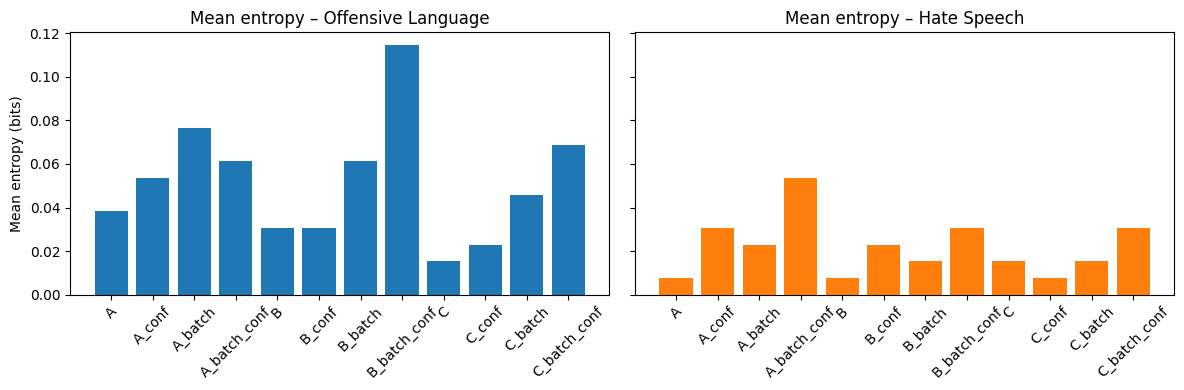

In [22]:
# Visualize Entropy
import pandas as pd
import matplotlib.pyplot as plt

# palette and ordering
palette = {'OL': '#1f77b4', 'HS': '#ff7f0e'}
condition_order = [
    'A', 'A_conf', 'A_batch', 'A_batch_conf',
    'B', 'B_conf', 'B_batch', 'B_batch_conf',
    'C', 'C_conf', 'C_batch', 'C_batch_conf'
]

# make sure the rows follow that order
mean_entropies = (
    mean_entropy_wide
      .set_index('cond_clean')
      .reindex(condition_order)
)

# ---------------- side-by-side plots -----------------
fig, axes = plt.subplots(
    nrows=1, ncols=2, figsize=(12, 4), sharey=True     # 1×2 layout
)

# Offensive-language entropy
axes[0].bar(
    mean_entropies.index,
    mean_entropies['mean_entropy_OL'],
    color=palette['OL']
)
axes[0].set_title('Mean entropy – Offensive Language')
axes[0].set_ylabel('Mean entropy (bits)')
axes[0].tick_params(axis='x', rotation=45)

# Hate-speech entropy
axes[1].bar(
    mean_entropies.index,
    mean_entropies['mean_entropy_HS'],
    color=palette['HS']
)
axes[1].set_title('Mean entropy – Hate Speech')
axes[1].tick_params(axis='x', rotation=45)

fig.tight_layout()
plt.show()

<a id="certainty_2"></a>
## Approach 2 to certainty assessment (conf conditions) - LLM self-reported Confidence

i.e., Group by Tweet and Condition and Calculate the mean self-reported confidence scores
e.g.   
tweet A in condition X: OL-Confidence-Scores: 4, 3, 4 --> Confidenc: = 3.66
tweet 4 in condition X: OL-Confidence-Scores: 4, 4, 4 --> Confidenc: = 4.00combined_df

In [161]:
def extract_numbers(score):
    # If the score is a string, convert it to a list using eval
    if isinstance(score, str):
        score_list = eval(score)
    else:
        score_list = [score]  # in case the score is already a single value (int/float)

    # Convert the list of strings to a list of floats
    return [float(s) for s in score_list]
# Apply the function to extract the numbers
combined_df['R1_score_cleaned'] = combined_df['R1_score'].apply(extract_numbers)
combined_df['R2_score_cleaned'] = combined_df['R2_score'].apply(extract_numbers)
combined_df['R3_score_cleaned'] = combined_df['R3_score'].apply(extract_numbers)

combined_df['R3_score_cleaned'].str[1]


3200    90.0
3201    90.0
3202     NaN
3203     NaN
3204    80.0
        ... 
5115     NaN
5116     NaN
5117     NaN
5118     NaN
5119     NaN
Name: R3_score_cleaned, Length: 1920, dtype: float64

In [158]:
# confidence_df.loc[1, 'R1_score'].str.split(expand=True).iloc[:, [0, 1]]
confidence_df.loc[is_A, 'R1_score'].str[0]

3200    [
3204    [
3216    [
3220    [
3232    [
       ..
5076    [
5088    [
5092    [
5104    [
5108    [
Name: R1_score, Length: 240, dtype: object

In [178]:
# Create DF for confidencs score investigation 
# --> i.e., merge the C.OL and C.HS conditions to one condition
# base df
confidence_df = combined_df[combined_df['condition'].str.contains(r"conf", case=False, na=False)][
    ['batch_id', 'tweet_in_batch', 'tweet_id',  'tweet', 
     'condition', 
     'shot', 
     'R1_label', 'R2_label', 'R3_label',
     'R1_score', 'R2_score', 'R3_score']].copy()

key_cols = ["batch_id", "tweet_in_batch", "tweet_id", 
            "tweet", "condition", "shot",
            "R1_label", "R2_label", "R3_label",
            'R1_score', 'R2_score', 'R3_score',
            "cond_clean"]

# extract binary OL and HS labels for every row 
confidence_df['R1_OL'] = np.where(confidence_df['R1_label'].str.contains(r'(?<!N)OL'), 1, 0)
confidence_df['R2_OL'] = np.where(confidence_df['R2_label'].str.contains(r'(?<!N)OL'), 1, 0)
confidence_df['R3_OL'] = np.where(confidence_df['R3_label'].str.contains(r'(?<!N)OL'), 1, 0)

confidence_df['R1_HS'] = np.where(confidence_df['R1_label'].str.contains(r'(?<!N)HS'), 1, 0)
confidence_df['R2_HS'] = np.where(confidence_df['R2_label'].str.contains(r'(?<!N)HS'), 1, 0)
confidence_df['R3_HS'] = np.where(confidence_df['R3_label'].str.contains(r'(?<!N)HS'), 1, 0)




def extract_numbers(score):
    # If the score is a string, convert it to a list using eval
    if isinstance(score, str):
        score_list = eval(score)
    else:
        score_list = [score]  # in case the score is already a single value (int/float)

    # Convert the list of strings to a list of floats
    return [float(s) for s in score_list]
# Apply the function to extract the numbers
confidence_df['R1_score_cleaned'] = confidence_df['R1_score'].apply(extract_numbers)
confidence_df['R2_score_cleaned'] = confidence_df['R2_score'].apply(extract_numbers)
confidence_df['R3_score_cleaned'] = confidence_df['R3_score'].apply(extract_numbers)


combined_df.head(2)


# Handle condition A (first = OL, second = HS)
is_A = confidence_df['condition'].str.contains('A')
confidence_df.loc[is_A, ['R1_OL_confidence']] = confidence_df.loc[is_A, 'R1_score_cleaned'].str[0]
confidence_df.loc[is_A, ['R1_HS_confidence']] = confidence_df.loc[is_A, 'R1_score_cleaned'].str[1]

confidence_df.loc[is_A, ['R2_OL_confidence']] = confidence_df.loc[is_A, 'R2_score_cleaned'].str[0]
confidence_df.loc[is_A, ['R2_HS_confidence']] = confidence_df.loc[is_A, 'R2_score_cleaned'].str[1]

confidence_df.loc[is_A, ['R3_OL_confidence']] = confidence_df.loc[is_A, 'R3_score_cleaned'].str[0]
confidence_df.loc[is_A, ['R3_HS_confidence']] = confidence_df.loc[is_A, 'R3_score_cleaned'].str[1]

# Handle condition B (first = HS, second = OL)
is_B = confidence_df['condition'].str.contains('B')
confidence_df.loc[is_B, ['R1_OL_confidence']] = confidence_df.loc[is_B, 'R1_score_cleaned'].str[1]
confidence_df.loc[is_B, ['R1_HS_confidence']] = confidence_df.loc[is_B, 'R1_score_cleaned'].str[0]

confidence_df.loc[is_B, ['R2_OL_confidence']] = confidence_df.loc[is_B, 'R2_score_cleaned'].str[1]
confidence_df.loc[is_B, ['R2_HS_confidence']] = confidence_df.loc[is_B, 'R2_score_cleaned'].str[0]

confidence_df.loc[is_B, ['R3_OL_confidence']] = confidence_df.loc[is_B, 'R3_score_cleaned'].str[1]
confidence_df.loc[is_B, ['R3_HS_confidence']] = confidence_df.loc[is_B, 'R3_score_cleaned'].str[0]


# Handle condition C.OL (OL only)
is_C_OL = confidence_df['condition'].str.contains('C.OL')
confidence_df.loc[is_C_OL, ['R1_OL_confidence']] = confidence_df.loc[is_C_OL, 'R1_score_cleaned'].str[0]
confidence_df.loc[is_C_OL, ['R1_HS_confidence']] = confidence_df.loc[is_C_OL, 'R1_score_cleaned'].str[1]

confidence_df.loc[is_C_OL, ['R2_OL_confidence']] = confidence_df.loc[is_C_OL, 'R2_score_cleaned'].str[0]
confidence_df.loc[is_C_OL, ['R2_HS_confidence']] = confidence_df.loc[is_C_OL, 'R2_score_cleaned'].str[1]

confidence_df.loc[is_C_OL, ['R3_OL_confidence']] = confidence_df.loc[is_C_OL, 'R3_score_cleaned'].str[0]
confidence_df.loc[is_C_OL, ['R3_HS_confidence']] = confidence_df.loc[is_C_OL, 'R3_score_cleaned'].str[1]


# Handle condition C.HS (HS only)
is_C_HS = confidence_df['condition'].str.contains('C.HS')
confidence_df.loc[is_C_HS, ['R1_OL_confidence']] = confidence_df.loc[is_C_HS, 'R1_score_cleaned'].str[1]
confidence_df.loc[is_C_HS, ['R1_HS_confidence']] = confidence_df.loc[is_C_HS, 'R1_score_cleaned'].str[0]

confidence_df.loc[is_C_HS, ['R2_OL_confidence']] = confidence_df.loc[is_C_HS, 'R2_score_cleaned'].str[1]
confidence_df.loc[is_C_HS, ['R2_HS_confidence']] = confidence_df.loc[is_C_HS, 'R2_score_cleaned'].str[0]

confidence_df.loc[is_C_HS, ['R3_OL_confidence']] = confidence_df.loc[is_C_HS, 'R3_score_cleaned'].str[1]
confidence_df.loc[is_C_HS, ['R3_HS_confidence']] = confidence_df.loc[is_C_HS, 'R3_score_cleaned'].str[0]





# create additional C. col for C.HS and C.OL cases
confidence_df['cond_clean'] = confidence_df['condition'].str.replace(r'\.OL|\.HS', '', regex=True)


# A & B conditions --> nothing special to do --> join binary ratings
confidence_df_A_B = confidence_df[confidence_df['condition']
                            .str.contains(r'[AB]', na=False)].copy()[key_cols]
confidence_df_A_B = confidence_df_A_B.merge(confidence_df[['tweet', 'cond_clean', 
                                                  'R1_OL', 'R2_OL', 'R3_OL',
                                                  'R1_HS', 'R2_HS', 'R3_HS', 
                                                  'R1_OL_confidence', 
                                                  'R2_OL_confidence', 
                                                  'R3_OL_confidence', 
                                                  'R1_HS_confidence', 
                                                  'R2_HS_confidence', 
                                                  'R3_HS_confidence']], 
                   left_on=['tweet', 'cond_clean'], 
                   right_on=['tweet', 'cond_clean'])

# C conditions --> sepcial: join binary OL ratings from C.OL base df 
#                           same for binary HS ratings
confidence_df_C = confidence_df[key_cols].copy().drop_duplicates(subset=['tweet_id', 'cond_clean'])

# join binary OL ratings
confidence_df_C = confidence_df_C.merge(confidence_df[confidence_df['condition'].str.contains(r'C\.OL', na=False)]
                                  [['tweet', 'cond_clean', 'R1_OL', 'R2_OL', 'R3_OL',
                                   'R1_OL_confidence', 'R2_OL_confidence', 'R3_OL_confidence']], 
                   left_on=['tweet', 'cond_clean'], 
                   right_on=['tweet', 'cond_clean'])
# join binary HS ratings
confidence_df_C = confidence_df_C.merge(confidence_df[confidence_df['condition'].str.contains(r'C\.HS', na=False)]
                                  [['tweet', 'cond_clean', 'R1_HS', 'R2_HS', 'R3_HS',
                                   'R1_HS_confidence', 'R2_HS_confidence', 'R3_HS_confidence']], 
                   left_on=['tweet', 'cond_clean'], 
                   right_on=['tweet', 'cond_clean'])


# Concat to get the final reformatted df for calculating entropies
confidence_df = pd.concat([confidence_df_A_B, confidence_df_C], 
                       ignore_index=True, sort=False)


# Checks: --> the number of C rows should have halved --> WORKS 
print(confidence_df_A_B.shape)
print(confidence_df_C.shape)
print(confidence_df.shape)
# confidence_df.head()


##########
### WEITER AB HIER --> PRÜFEN OB DER C CONDITION CODE AUCH DAS MACHT WAS ER SOLL! 
#########




# # Handle condition C.OL (OL score is in R1_score)
# is_C_OL = confidence_df['condition'].str.contains('C.OL')
# confidence_df.loc[is_C_OL, ['R1_OL_confidence', 'R2_OL_confidence', 'R3_OL_confidence']] = confidence_df.loc[is_C_OL, ['R1_score', 'R2_score', 'R3_score']]

# # Handle condition C.HS (HS score is in R1_score)
# is_C_HS = confidence_df['condition'].str.contains('C.HS')
# confidence_df.loc[is_C_HS, ['R1_HS_confidence', 'R2_HS_confidence', 'R3_HS_confidence']] = confidence_df.loc[is_C_HS, ['R1_score', 'R2_score', 'R3_score']]




# # Function to clean and convert the string representation of lists into numeric values
# def clean_and_convert_score(score):
#     # Convert string representation of list into actual list (e.g., "['95', '80']" -> [95, 80])
#     score_list = eval(score) if isinstance(score, str) else score
#     # Convert to numeric, handle cases where there's only one score or missing values
#     return [float(s) for s in score_list] if isinstance(score_list, list) else [float(score_list)]

# # Apply the cleaning and conversion function to the score columns
# confidence_df['R1_score_cleaned'] = confidence_df['R1_score'].apply(clean_and_convert_score)
# confidence_df['R2_score_cleaned'] = confidence_df['R2_score'].apply(clean_and_convert_score)
# confidence_df['R3_score_cleaned'] = confidence_df['R3_score'].apply(clean_and_convert_score)

# # Now, we need to split the scores according to the conditions (A, B, C.OL, C.HS)
# def split_scores_conditionally(row, condition):
#     if condition == 'A':  # OL first, then HS
#         return pd.Series([row[0], row[1]])  # [OL_score, HS_score]
#     elif condition == 'B':  # HS first, then OL
#         return pd.Series([row[1], row[0]])  # [HS_score, OL_score]
#     elif condition == 'C.OL':  # Only OL scores, ignore HS
#         return pd.Series([row[0], None])  # [OL_score, NaN]
#     elif condition == 'C.HS':  # Only HS scores, ignore OL
#         return pd.Series([None, row[0]])  # [NaN, HS_score]

# # Apply the split based on conditions
# confidence_df[['R1_confidence_1', 'R1_confidence_2']] = confidence_df.apply(lambda row: split_scores_conditionally(row['R1_score_cleaned'], row['condition']), axis=1)
# confidence_df[['R2_confidence_1', 'R2_confidence_2']] = confidence_df.apply(lambda row: split_scores_conditionally(row['R2_score_cleaned'], row['condition']), axis=1)
# confidence_df[['R3_confidence_1', 'R3_confidence_2']] = confidence_df.apply(lambda row: split_scores_conditionally(row['R3_score_cleaned'], row['condition']), axis=1)

# import ace_tools as tools; tools.display_dataframe_to_user(name="Cleaned Confidence Scores", dataframe=df)

# # Display the resulting dataframe with cleaned and split confidence scores
# df[['R1_score', 'R1_score_cleaned', 'R1_confidence_1', 'R1_confidence_2', 
#     'R2_score', 'R2_score_cleaned', 'R2_confidence_1', 'R2_confidence_2', 
#     'R3_score', 'R3_score_cleaned', 'R3_confidence_1', 'R3_confidence_2']]



# # Handle condition A (first = OL, second = HS)
# is_A = confidence_df['condition'].str.contains('A')
# confidence_df.loc[is_A, ['R1_OL_confidence', 'R1_HS_confidence']] = confidence_df.loc[is_A, 'R1_score'].str.split(expand=True).iloc[:, [0, 1]]
# confidence_df.loc[is_A, ['R2_OL_confidence', 'R2_HS_confidence']] = confidence_df.loc[is_A, 'R2_score'].str.split(expand=True).iloc[:, [0, 1]]
# confidence_df.loc[is_A, ['R3_OL_confidence', 'R3_HS_confidence']] = confidence_df.loc[is_A, 'R3_score'].str.split(expand=True).iloc[:, [0, 1]]

# # Handle condition B (first = HS, second = OL)
# is_B = confidence_df['condition'].str.contains('B')
# confidence_df.loc[is_B, ['R1_HS_confidence', 'R1_OL_confidence']] = confidence_df.loc[is_B, 'R1_score'].str.split(expand=True).iloc[:, [0, 1]]
# confidence_df.loc[is_B, ['R2_HS_confidence', 'R2_OL_confidence']] = confidence_df.loc[is_B, 'R2_score'].str.split(expand=True).iloc[:, [0, 1]]
# confidence_df.loc[is_B, ['R3_HS_confidence', 'R3_OL_confidence']] = confidence_df.loc[is_B, 'R3_score'].str.split(expand=True).iloc[:, [0, 1]]

# # Handle condition C.OL (OL score is in R1_score)
# is_C_OL = confidence_df['condition'].str.contains('C.OL')
# confidence_df.loc[is_C_OL, ['R1_OL_confidence', 'R2_OL_confidence', 'R3_OL_confidence']] = confidence_df.loc[is_C_OL, ['R1_score', 'R2_score', 'R3_score']]

# # Handle condition C.HS (HS score is in R1_score)
# is_C_HS = confidence_df['condition'].str.contains('C.HS')
# confidence_df.loc[is_C_HS, ['R1_HS_confidence', 'R2_HS_confidence', 'R3_HS_confidence']] = confidence_df.loc[is_C_HS, ['R1_score', 'R2_score', 'R3_score']]

(480, 25)
(240, 25)
(720, 25)


In [186]:
# Get Mean Confidence Scores per Tweet and Condition
confidence_df['mean_tweet_conf_OL'] = (confidence_df[
    ['R1_OL_confidence', 'R2_OL_confidence', 'R3_OL_confidence']]
                                       .mean(axis=1, numeric_only=True))

confidence_df['mean_tweet_conf_HS'] = (confidence_df[
    ['R1_HS_confidence', 'R2_HS_confidence', 'R3_HS_confidence']]
                                       .mean(axis=1, numeric_only=True))

# Calculcate Mean Entropies per condition and Outcome (HS/OL)
mean_confidence_wide = (
    confidence_df.groupby('cond_clean', as_index=False)
      .agg(mean_confidence_OL = ('mean_tweet_conf_OL', 'mean'),
           mean_confidence_HS = ('mean_tweet_conf_HS', 'mean'))
)
mean_confidence_wide.head(10)

# maybe plot distribution instead of confidence values?

,cond_clean,mean_confidence_OL,mean_confidence_HS
0,A_batch_conf,90.375000,87.861111
1,A_conf,91.041667,91.500000
2,B_batch_conf,92.222222,86.475000
3,B_conf,91.152778,93.333333
4,C_batch_conf,88.569444,83.555556
5,C_conf,93.527778,83.791667


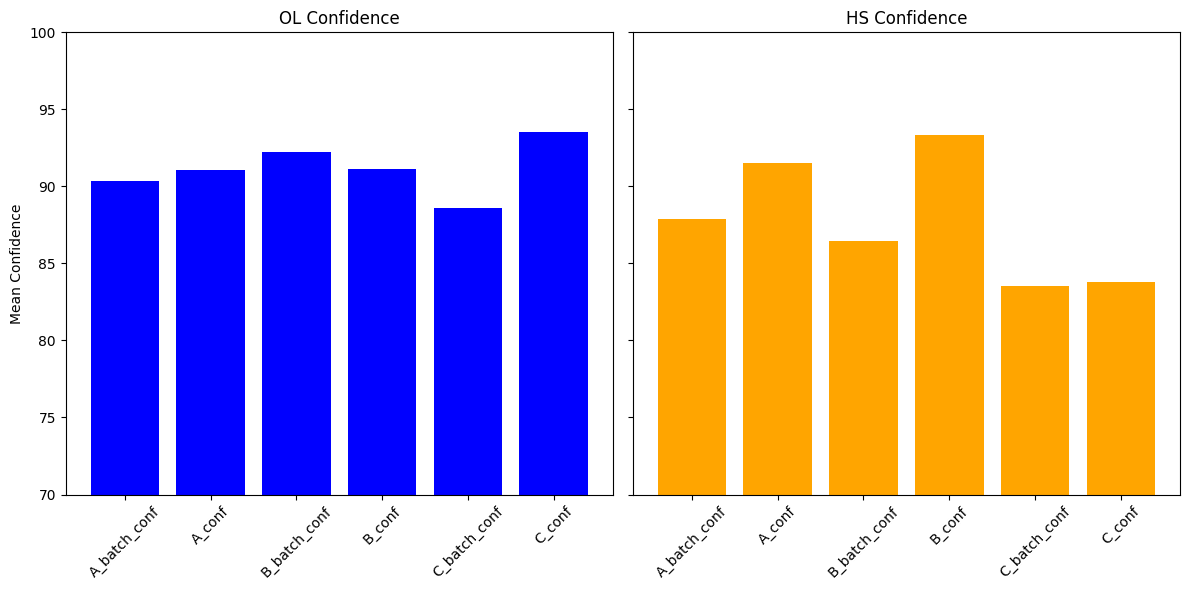

In [189]:
### PLOT
# Separate normal and batch conditions
normal_conditions = mean_confidence_wide[mean_confidence_wide['cond_clean'].str.contains("_conf$")]
batch_conditions = mean_confidence_wide[mean_confidence_wide['cond_clean'].str.contains("_batch_conf")]

# Sort conditions alphabetically by label (A, B, C)
normal_conditions = normal_conditions.sort_values(by="cond_clean")
batch_conditions = batch_conditions.sort_values(by="cond_clean")

# Concatenate for desired order: normal first, then batch
ordered_df = pd.concat([normal_conditions, batch_conditions])

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

# Barplot for OL
axes[0].bar(ordered_df['cond_clean'], ordered_df['mean_confidence_OL'], color='blue')
axes[0].set_title('OL Confidence')
axes[0].set_ylabel('Mean Confidence')
axes[0].tick_params(axis='x', rotation=45)

# Barplot for HS
axes[1].bar(ordered_df['cond_clean'], ordered_df['mean_confidence_HS'], color='orange')
axes[1].set_title('HS Confidence')
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_ylim(70, 100)  # Set y-axis limit from 60 to 90

plt.tight_layout()
plt.show()
# self reported confidences seem to not be affected at all by the different conditions

<a id="certainty_3"></a>
## Approach 3 to certainty assessment (only non-batch conditions) - LogProb Comparison

i.e., extract the logprobs for the next tokens 
e.g.   
tweet A in condition X: OL-Confidence-Scores: 4, 3, 4 --> Confidenc: = 3.66
tweet 4 in condition X: OL-Confidence-Scores: 4, 4, 4 --> Confidenc: = 4.00combined_df